# Semiparametric Estimation of BSM Parameters and PDF

**Model:**  
$$\bm{y}= [y_1,\dots,y_n]^\top \sim \mathcal{N}\bigl(\bm{\mu}(c),\, \Sigma\bigr)$$
$$y_i = \bm{y}(x_i, Q_i^2), \quad \mu_{i}(c) = v(c;Q^2_i)\,T[f], \quad i=1,\dots,n$$

where
- $v(c;Q^2) = 1 + k_{\rm lin}(Q^2)\,c + k_{\rm quad}(Q^2)\,c^2$ encodes new-physics EFT corrections,
- $T[f]$ is the standard-model theory prediction convolved with the PDF $f$,
- $f(x)$ (or $xf(x)$) is expanded in a B-spline basis: $f(x) = \sum_k \beta_k B_k(x)$, subject to $\sum_k w_k\beta_k = 1$.

**Goal:** estimate $c$ while treating $f$ as an infinite-dimensional nuisance function.

**Outline**
1. Load Grid/FK Tables
2. Model Configuration
3. True PDF (from LHAPDF)
4. Theory Predictions & Data Generation
5. Fitting
   - 5a. B-spline Basis
   - 5b. Option A — Separate Fit (β first, then c)
   - 5c. Option B — Joint Fit (β and c simultaneously)
   - 5d. One-step Estimator
6. Results
7. Simulation Study
8. Uncertainty Quantification

In [1]:
import numpy as np
from scipy.integrate import fixed_quad, quad
from scipy.stats import norm
from scipy.linalg import cho_factor, cho_solve
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from collections import defaultdict
import lhapdf

from T3_utils import (
    # Basis
    bspline_basis,
    # Model
    klin, kquad, v_c, v_prime_c,
    # Design matrices & theory
    build_f_design_matrix_FK, build_yf_design_matrix_FK,
    build_K_matrix, build_K_prime_matrix,
    T_sm_FK, true_mean, true_mean_basis,
    # Fitting
    fit_beta_c, mle_beta, mle_c, one_step_c, one_step_confidence_interval, bootstrap_confidence_interval,
    # Plotting
    plot_by_Q2,
    # Experiment runners
    setup_experiment, run_single_experiment,
)

---
## 1. Load Grid/FK Table

The grid/FK table is precomputed by `data_T3.py` and stored as a compressed NumPy archive.  
Key arrays:
- `W` — FK table matrix `(N_data, N_grid)`: encodes the DIS cross-section convolution
- `grid` — x-grid `(N_grid,)` that `W` integrates over
- `Sigma` — experimental covariance matrix `(N_data, N_data)`
- `kinematics` — `(N_data, 2)` array of `(x, Q²)` pairs for each data point

In [2]:
data = np.load("Dataset/data_208.npz")

Q0     = data["Q0"]         # reference scale
grid   = data["grid"]       # x-grid for FK table
W      = data["W"]          # FK table  (N_data, N_grid)
Sigma  = data["Sigma"]      # covariance (N_data, N_data)
xQ2    = data["kinematics"] # (x, Q²) pairs  (N_data, 2)
y_vals = data["y_vals"]      # y values (N_data,)
F2_d   = data["F2_d"]       # F2 values (N_data,)

print(f"N_data = {xQ2.shape[0]},  N_grid = {grid.shape[0]}")
print(f"Q² range: [{xQ2[:,1].min():.1f}, {xQ2[:,1].max():.1f}]")

N_data = 248,  N_grid = 50
Q² range: [8.8, 230.0]


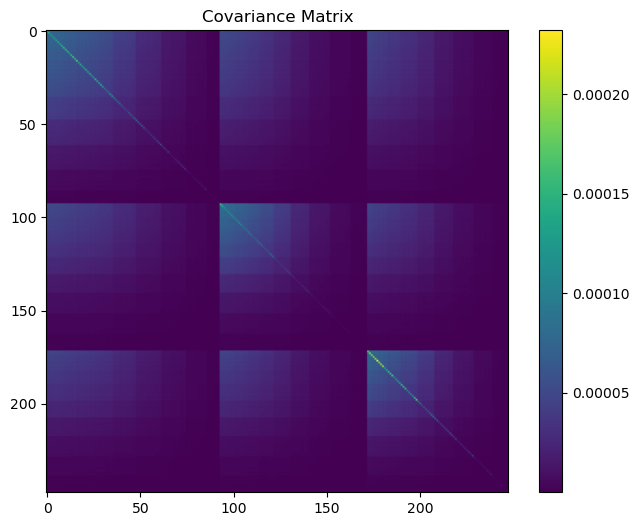

In [3]:
# visualize Sigma
plt.figure(figsize=(8, 6))
plt.imshow(Sigma, cmap='viridis')
plt.colorbar()
plt.title('Covariance Matrix')
plt.show()

Plot the kinematic coverage of the data:

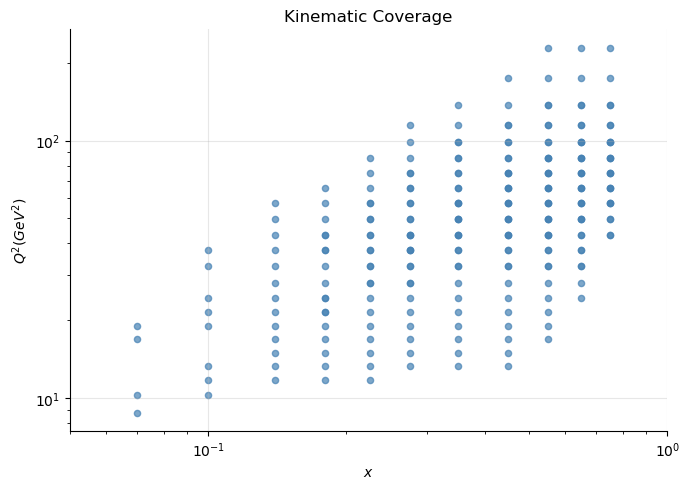

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(xQ2[:, 0], xQ2[:, 1], s=20, color="steelblue", alpha=0.7)
ax.set_xlabel("$x$")
ax.set_ylabel("$Q^2 (GeV^2)$")
ax.set_title("Kinematic Coverage")

ax.set_xlim(5e-2, 1)
ax.set_xscale("log")
ax.set_yscale("log")

ax.grid(True, which="major", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

fig.savefig("../results/kinematic_coverage.pdf", bbox_inches="tight")

Check the singular values of `W`. The number of basis functions should not exceed the number of significant singular values to avoid overfitting.

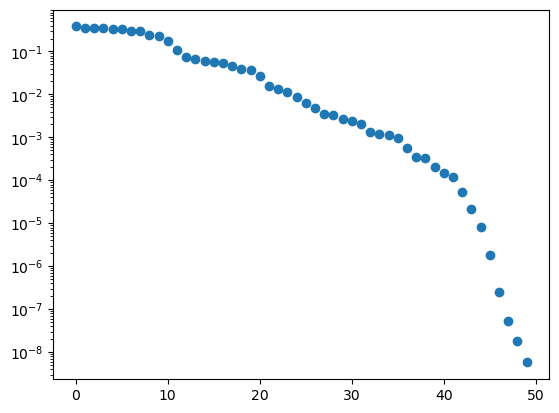

In [5]:
plt.plot(np.round(np.linalg.svd(W)[1],20), 'o')
plt.yscale('log')

---
## 2. Model Configuration

The EFT expansion uses two momentum-suppressed Wilson coefficients:
$$k_{\rm lin}(Q^2) = \frac{Q^2}{\Lambda^2}, \qquad k_{\rm quad}(Q^2) = \frac{Q^4}{\Lambda^4}$$

giving the polynomial factor $v(c;Q^2) = 1 + k_{\rm lin}\,c + k_{\rm quad}\,c^2$.

These are already implemented in `T3_utils` with `Lambda=100` as the default.

In [6]:
Lambda  = 100
Q2_min  = xQ2[:, 1].min()
Q2_max  = xQ2[:, 1].max()

# Wrap klin/kquad so Lambda is fixed for this experiment
_klin  = lambda z: klin(z,  Lambda=Lambda)
#_klin = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
#_kquad = lambda z: kquad(z, Lambda=Lambda)
_kquad = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
_v_c       = lambda c, xQ2: v_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=_klin, kquad=_kquad)

# Sanity check: v(c=0) should be 1 everywhere
assert np.allclose(_v_c(0, xQ2), 1.0)

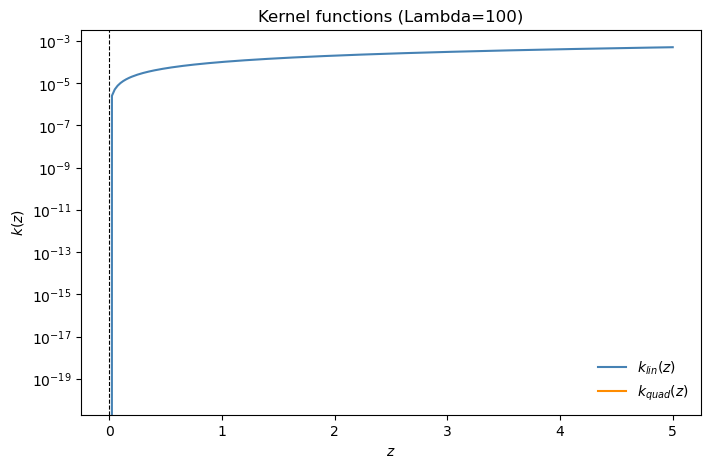

In [7]:
# Plot klin and kquad
z = np.linspace(0, 5, 200)
plt.figure(figsize=(8, 5))
plt.plot(z, _klin(z), label="$k_{lin}(z)$", color="steelblue")
plt.plot(z, _kquad(z), label="$k_{quad}(z)$", color="darkorange")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("$z$"); plt.ylabel("$k(z)$")
plt.yscale("log")
plt.title(f"Kernel functions (Lambda={Lambda})")
plt.legend(frameon=False)

---
## 3. True PDF (from LHAPDF)

We use $T_3$ PDF from the NNPDF4.0 set as the ground-truth PDF:
$$T_3(y) = (u(y)+\bar{u}(y)) - (d(y)+\bar{d}(y)).$$

In [8]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf    = lhapdf.mkPDF(pdfset, 0)

x_min = pdf.xMin
x_max = pdf.xMax
Q2_0  = Q0 ** 2

def _uv_scalar(x, Q2):
    return pdf.xfxQ2(2, x, Q2) / x + pdf.xfxQ2(-2, x, Q2) / x

def _dv_scalar(x, Q2):
    return pdf.xfxQ2(1, x, Q2) / x + pdf.xfxQ2(-1, x, Q2) / x

uv = np.vectorize(_uv_scalar, excluded={"Q2"})
dv = np.vectorize(_dv_scalar, excluded={"Q2"})

def f(x):
    return uv(x, Q2_0) - dv(x, Q2_0)

print(f"x range: [{x_min}, {x_max}]")
print("Integral of f over x range:", fixed_quad(f, x_min, x_max, n=1000)[0])

x range: [1e-09, 1.0]LHAPDF 6.5.5 loading /Users/richardzhs/miniforge3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat

NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100
Integral of f over x range: 0.78966468654706


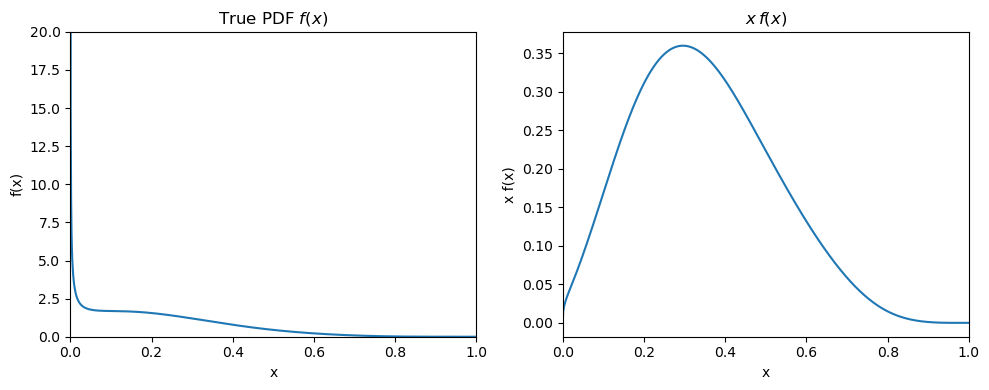

In [9]:
pt = np.linspace(x_min, x_max, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt))
ax1.set_xlim(0, 1); ax1.set_ylim(0, 20)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("True PDF $f(x)$")

ax2.plot(pt, pt * f(pt))
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel("x f(x)"); ax2.set_title("$x\,f(x)$")

plt.tight_layout(); plt.show()

---
## 4. Theory Predictions & Data Generation

The SM prediction is $T[f] = W \cdot f(\text{grid})$.  
The full mean at true $c$ is $\mu = v(c;\mathbf{Q}^2) \odot T[f]$.

In [10]:
# Standard-model theory prediction
T = T_sm_FK(f=f, W=W, grid=grid)

# True Wilson coefficient and full mean
c_true = 20
mu     = true_mean(c=c_true, T=T, xQ2=xQ2, klin=_klin, kquad=_kquad)

# Simulate one dataset
rng = np.random.default_rng(seed=42)
D   = rng.multivariate_normal(mean=mu, cov=Sigma)

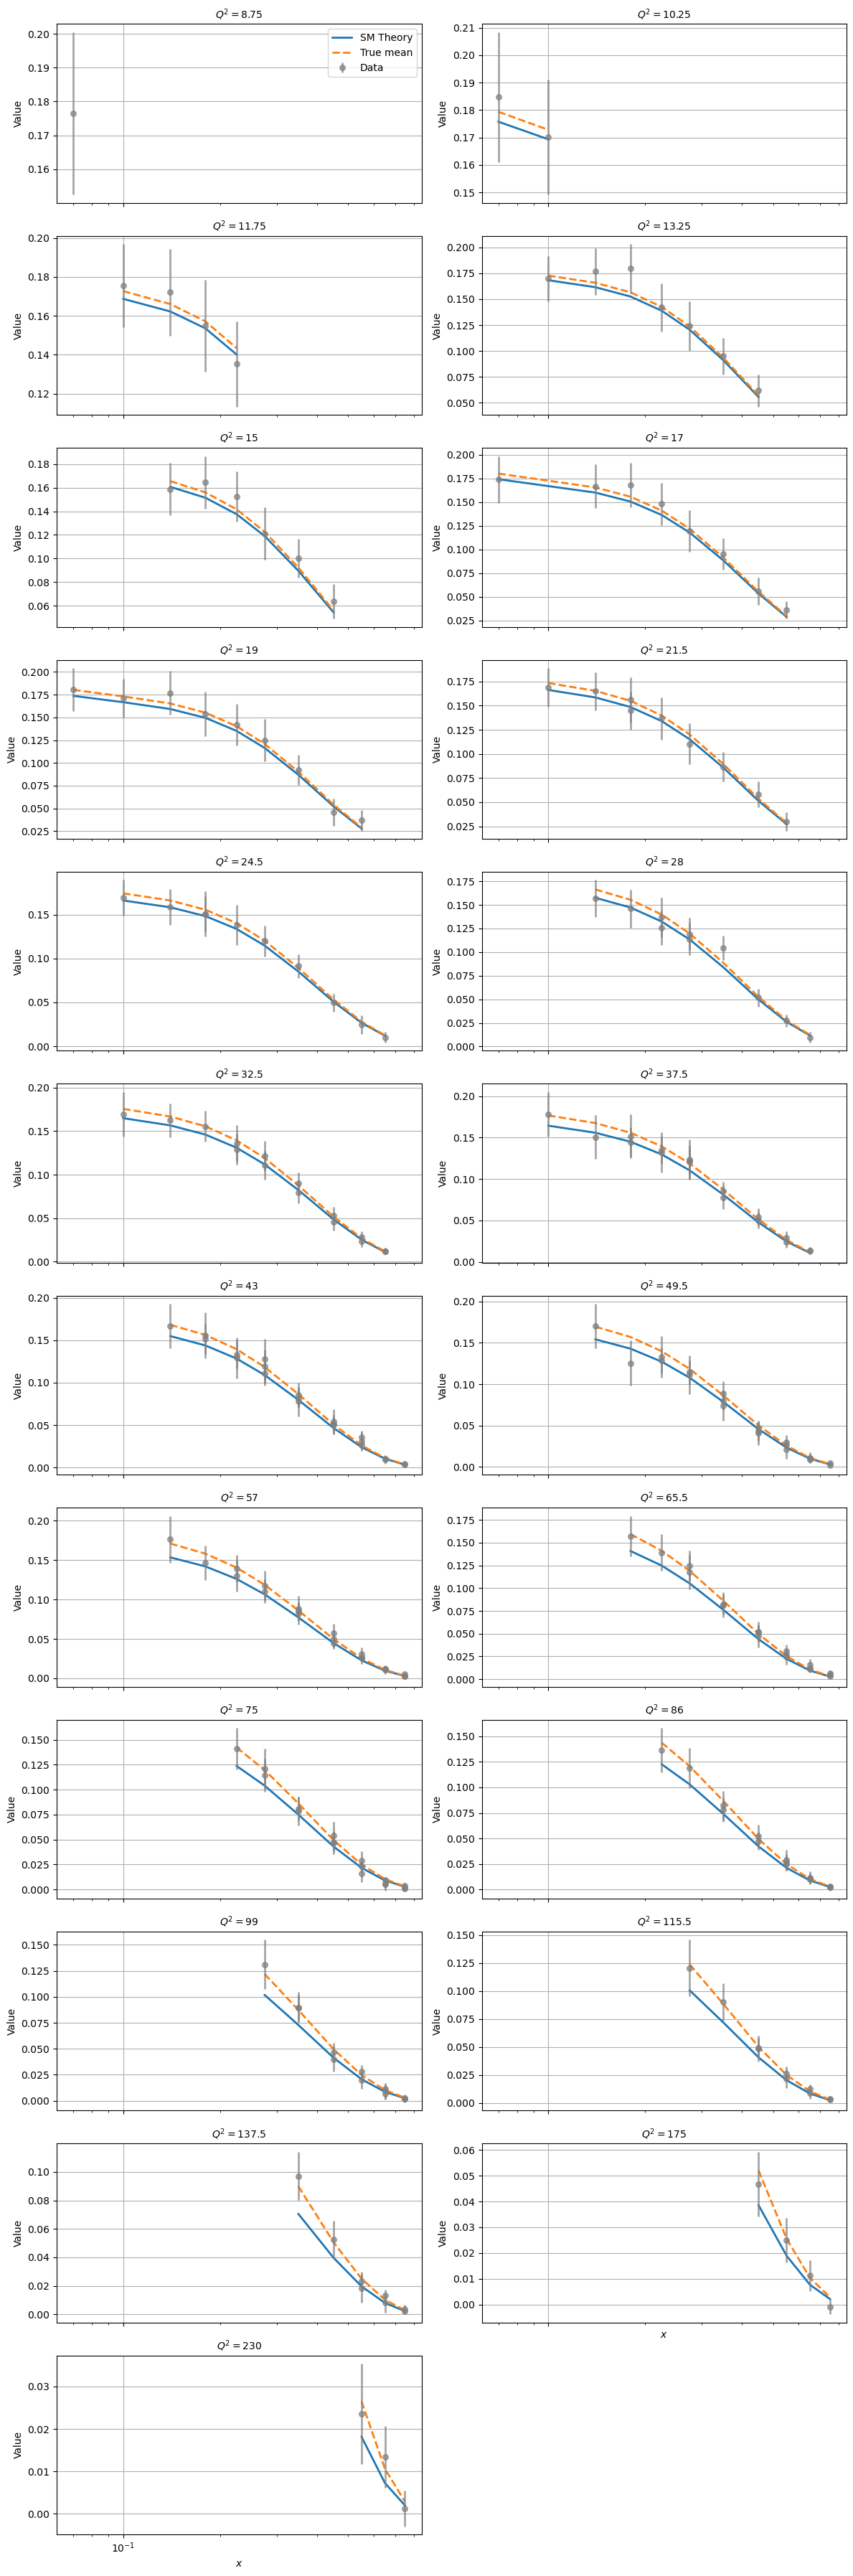

In [11]:
fig = plot_by_Q2(
    {"SM Theory": T, "True mean": mu, "Data": D},
    xQ2=xQ2, ncols=2, x_log_scale=True,
    series_styles={
        "SM Theory": dict(linestyle="-",  linewidth=2, color="C0"),
        "True mean": dict(linestyle="--", linewidth=2, color="C1"),
        "Data":      dict(kind="scatter", cov=Sigma, color="gray", s=30, alpha=0.7),
    }
)

---
## 5. Fitting

### 5a. B-spline Basis

Set `parametrize = "f"` to expand $f(x)$ directly, or `"xf"` to expand $xf(x)$.

**`"f"` mode:** $f(x) \approx \sum_k \beta_k B_k(x)$, normalization $\mathbf{w}^\top\boldsymbol{\beta}=1$ with $w_k = \int B_k(x)\,dx$.

**`"xf"` mode:** $xf(x) \approx \sum_k \beta_k B_k(x)$, so $f(x) = \frac{1}{x}\sum_k \beta_k B_k(x)$, normalization $w_k = \int B_k(x)/x\,dx$.

The design matrix $A \in \mathbb{R}^{N \times M}$ satisfies $T[f] \approx A\boldsymbol{\beta}$ in both cases.

In [12]:
degree      = 3    # cubic B-splines
M           = 10   # number of basis functions
parametrize = "xf"  # "f": expand f(x);  "xf": expand x*f(x)

B = bspline_basis(degree, M, x_min, x_max)

if parametrize == "f":
    w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])
    A      = build_f_design_matrix_FK(B=B, W=W, grid=grid)
elif parametrize == "xf":
    w_norm = np.array([quad(lambda y, Bk=Bk: Bk(y) / y, x_min, x_max)[0] for Bk in B])
    A      = build_yf_design_matrix_FK(B=B, W=W, grid=grid)
else:
    raise ValueError(f"parametrize must be 'f' or 'xf', got {parametrize!r}")

print(f"Parametrize : {parametrize}")
print(f"Design matrix shape: {A.shape}  (N_data × M)")
print(f"w_norm: {w_norm.round(4)}")

Parametrize : xf
Design matrix shape: (248, 10)  (N_data × M)
w_norm: [16.944   1.3863  0.7849  0.5573  0.3471  0.2555  0.2028  0.1302  0.0783
  0.0368]


### 5b. Option A — Separate Fit

**Step 1:** Fix $c = c_0$ (e.g. $c_0 = 0$) and find $\hat{\boldsymbol{\beta}}$ by minimizing the NLL over $\boldsymbol{\beta}$:
$$\hat{\boldsymbol{\beta}} = \arg\min_{\mathbf{w}^\top\boldsymbol{\beta}=1,\;\boldsymbol{\beta}\ge 0} \ell(\boldsymbol{\beta},\, c_0)$$

**Step 2:** Plug $\hat{\boldsymbol{\beta}}$ in and find $\hat{c}$ by minimizing the NLL over $c$:
$$\hat{c} = \arg\min_c\; \ell(\hat{\boldsymbol{\beta}},\, c)$$

This choice is physically well motivated: PDFs are extracted from global fits assuming the Standard Model (i.e., $c=0$), after which the fitted PDFs are used to determine the best-fit value of $c$.

In [16]:
# Step 1: fit beta with c fixed at c0=0
c0 = 0
beta_hat_sep, beta_history = mle_beta(
    D=D, A=A, c=c0, v=_v_c, xQ2=xQ2,
    Sigma=Sigma, w_norm=None,
    nonneg_beta=True, pin_endpoints=True,
    beta_opt="SLSQP", return_history=True, loss_scale=1e2,
)

# Step 2: fit c with beta fixed
c_hat_sep = mle_c(
    D=D, A=A, v=_v_c, beta=beta_hat_sep,
    xQ2=xQ2, Sigma=Sigma,
    c_opt="L-BFGS-B", c_range=(0, 100)
)

ci_sep_lower, ci_sep_upper, cb_sep = bootstrap_confidence_interval(
    A=A, xQ2=xQ2, Sigma=Sigma, w_norm=None, c0=c0,
    c_hat=c_hat_sep, beta_hat=beta_hat_sep, c_opt="L-BFGS-B", #c_range=(0, 100),
    n_boot=500, alpha=0.05, estimator="mle", loss_scale=1e2,
    klin=_klin, kquad=_kquad,
    opt="separate", verbose=True
)

print(f"True c            = {c_true}")
print(f"Separate fit c    = {c_hat_sep:.4f}")
print(f"95% CI (separate) = [{ci_sep_lower:.4f}, {ci_sep_upper:.4f}]")

  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
True c            = 20
Separate fit c    = 15.3279
95% CI (separate) = [11.3142, 19.3416]


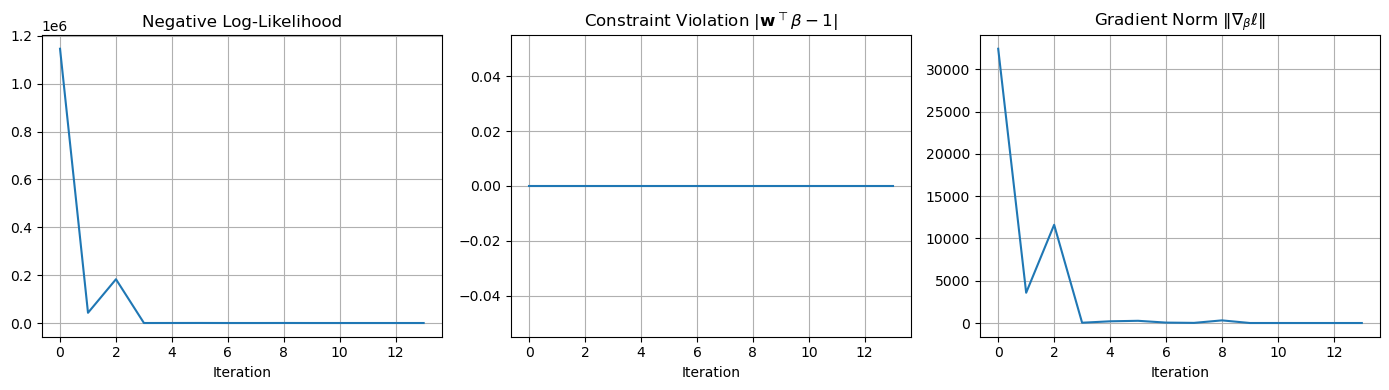

In [17]:
# Convergence diagnostics for the beta fit (separate fit)
beta_hist_df = pd.DataFrame(beta_history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(beta_hist_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(beta_hist_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(beta_hist_df["grad_norm"])
axes[2].set_title("Gradient Norm $\\|\\nabla_\\beta \\ell\\|$")
axes[2].set_xlabel("Iteration"); axes[2].grid()

plt.tight_layout(); plt.show()

Text(0, 0.5, 'NLL with $\\beta$ fixed')

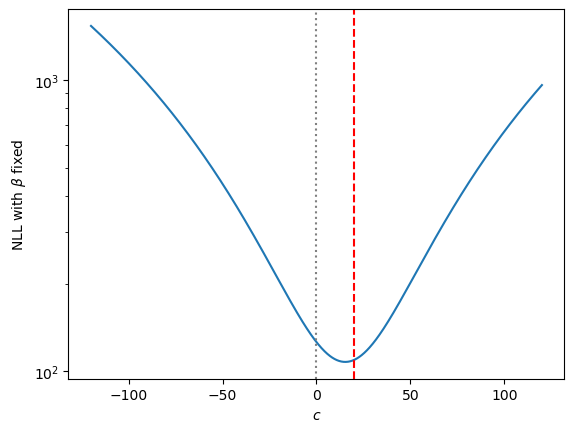

In [18]:
cf = cho_factor(Sigma)
t_beta = A @ beta_hat_sep

def c_nll(c):
    r = D - _v_c(c, xQ2) * t_beta
    return 0.5 * r @ cho_solve(cf, r)

c_grid = np.linspace(-120, 120, 1001)
losses = np.array([c_nll(c) for c in c_grid])

plt.plot(c_grid, losses)
plt.axvline(0, color="gray", linestyle=":")
plt.axvline(c_true, color="red", linestyle="--")
plt.yscale("log")
plt.xlabel("$c$")
plt.ylabel("NLL with $\\beta$ fixed")


### 5c. Option B — Joint Fit

Jointly minimize the NLL over $(\boldsymbol{\beta}, c)$ simultaneously:
$$\bigl(\hat{\boldsymbol{\beta}},\, \hat{c}\bigr) = \arg\min_{\mathbf{w}^\top\boldsymbol{\beta}=1,\;\boldsymbol{\beta}\ge 0}\; \ell(\boldsymbol{\beta},\, c)$$

In [19]:
res, history = fit_beta_c(
    D=D, A=A, v=_v_c, v_prime=_v_prime_c, c0=1,
    w_norm=None, xQ2=xQ2, Sigma=Sigma,
    nonneg_beta=True, pin_endpoints=True,
    return_history=True, opt_method="SLSQP", loss_scale=1e2
)

beta_hat_joint = res.beta_hat
c_hat_joint    = res.c_hat

ci_joint_lower, ci_joint_upper, cb_joint = bootstrap_confidence_interval(
    A=A, xQ2=xQ2, Sigma=Sigma, w_norm=None, c0=1,
    c_hat=c_hat_joint, beta_hat=beta_hat_joint,
    n_boot=500, alpha=0.05, estimator="mle", loss_scale=1e2,
    klin=_klin, kquad=_kquad,
    opt="joint", verbose=True
)

print(f"True c            = {c_true}")
print(f"Joint fit c       = {c_hat_joint:.4f}")
print(f"95% CI (joint)    = [{ci_joint_lower:.4f}, {ci_joint_upper:.4f}]")

  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
True c            = 20
Joint fit c       = 21.8525
95% CI (joint)    = [14.7960, 28.9090]


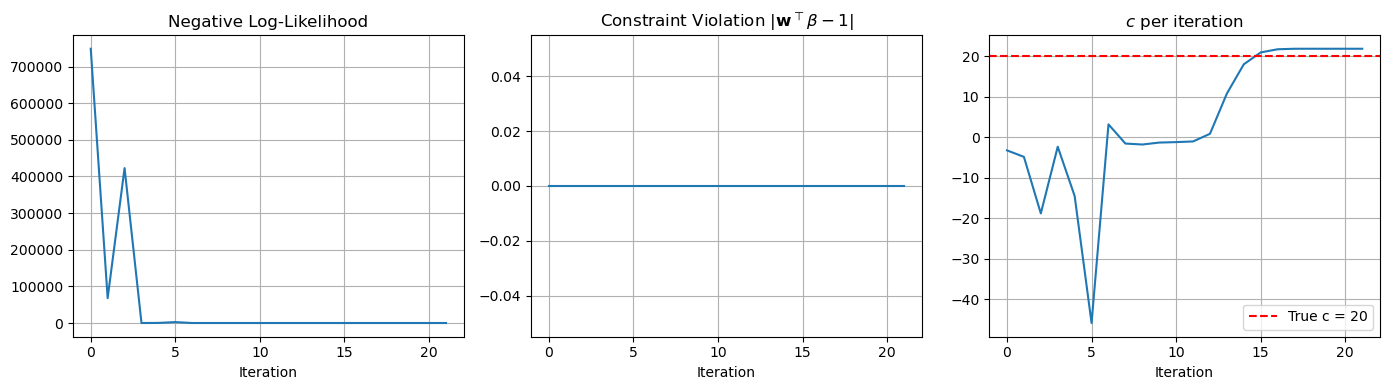

In [20]:
# Convergence diagnostics for the joint fit
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(history_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(history_df["c"])
axes[2].axhline(c_true, color="red", linestyle="--", label=f"True c = {c_true}")
axes[2].set_title("$c$ per iteration")
axes[2].set_xlabel("Iteration"); axes[2].legend(); axes[2].grid()

plt.tight_layout(); plt.show()

In [21]:
print(f"{'':20s}  {'c_hat':>10s}  {'95% CI':>20s}")
print(f"{'True c':20s}  {c_true:>10.4f}  {'—':>20s}")
print(f"{'Separate fit':20s}  {c_hat_sep:>10.4f}  {f'[{ci_sep_lower:.4f}, {ci_sep_upper:.4f}]':>20s}")
print(f"{'Joint fit':20s}  {c_hat_joint:>10.4f}  {f'[{ci_joint_lower:.4f}, {ci_joint_upper:.4f}]':>20s}")

                           c_hat                95% CI
True c                   20.0000                     —
Separate fit             15.3279    [11.3142, 19.3416]
Joint fit                21.8525    [14.7960, 28.9090]


**Choose which estimate to carry forward.**  
Edit the cell below to select `"separate"` or `"joint"`.

In [22]:
method = "separate"

if method == "joint":
    beta_hat, c_hat = beta_hat_joint, c_hat_joint
else:
    beta_hat, c_hat = beta_hat_sep, c_hat_sep

### 5d. One-step Estimator

The plug-in MLE $\hat c$ is biased due to the first-order bias from estimating the PDF function $f$.

The one-step estimator corrects this using the efficient influence function (EIF):
$$\hat c_{\rm one-step} = \hat c + \frac{\delta^\top \Sigma^{-1}(D - \hat\mu)}{\delta^\top \Sigma^{-1} \delta}$$
where $\delta = \partial_c \hat\mu - K h^*$ is the component of $\partial_c \hat\mu$ orthogonal to the nuisance tangent space $\{Kh : \mathbf{w}^\top h = 0\}$.

In [23]:
K       = build_K_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm=None, Sigma=Sigma)

ci_os_lower, ci_os_upper, _ = one_step_confidence_interval(info)

print(f"True c          = {c_true}")
print(f"MLE ({method:8s}) = {c_hat:.4f}  (error = {c_hat - c_true:+.4f})")
print(f"One-step        = {c_one_step:.4f}  (error = {c_one_step - c_true:+.4f})")
print(f"EIF correction  = {info['eif']:.4f}")
print(f"95% CI          = [{ci_os_lower:.4f}, {ci_os_upper:.4f}]")

True c          = 20
MLE (separate) = 15.3279  (error = -4.6721)
One-step        = 20.5485  (error = +0.5485)
EIF correction  = 5.2206
95% CI          = [13.7352, 27.3618]


---
## 6. Results

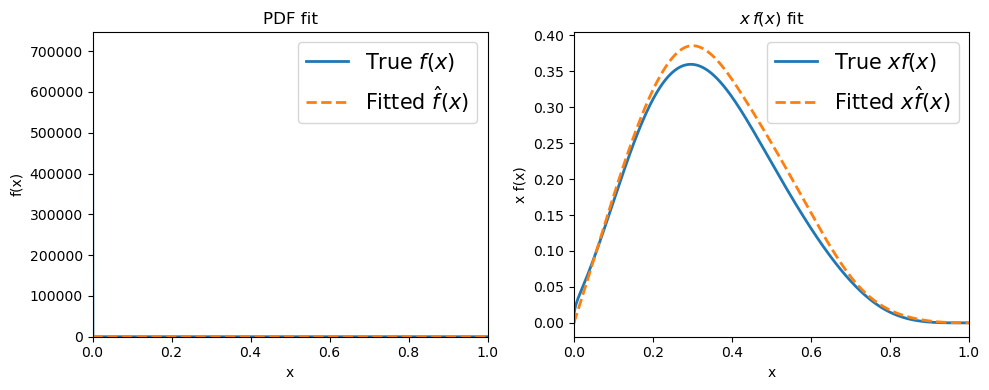

In [24]:
# PDF estimate vs truth
pt        = np.linspace(x_min, x_max, 1000)
basis_hat = sum(b * Bk(pt) for b, Bk in zip(beta_hat, B))
f_hat     = basis_hat if parametrize == "f" else basis_hat / pt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt),   lw=2, label="True $f(x)$")
ax1.plot(pt, f_hat,   lw=2, ls="--", label=r"Fitted $\hat f(x)$")
ax1.set_xlim(0, 1); ax1.set_ylim(0, None)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("PDF fit"); ax1.legend(fontsize=15)

ax2.plot(pt, pt * f(pt),   lw=2, label="True $x f(x)$")
ax2.plot(pt, pt * f_hat,   lw=2, ls="--", label=r"Fitted $x\hat f(x)$")
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel("x f(x)"); ax2.set_title("$x\,f(x)$ fit"); ax2.legend(fontsize=15)

plt.tight_layout(); plt.show()

In [ ]:
#import importlib
#import T3_utils
#importlib.reload(T3_utils)
#from T3_utils import *

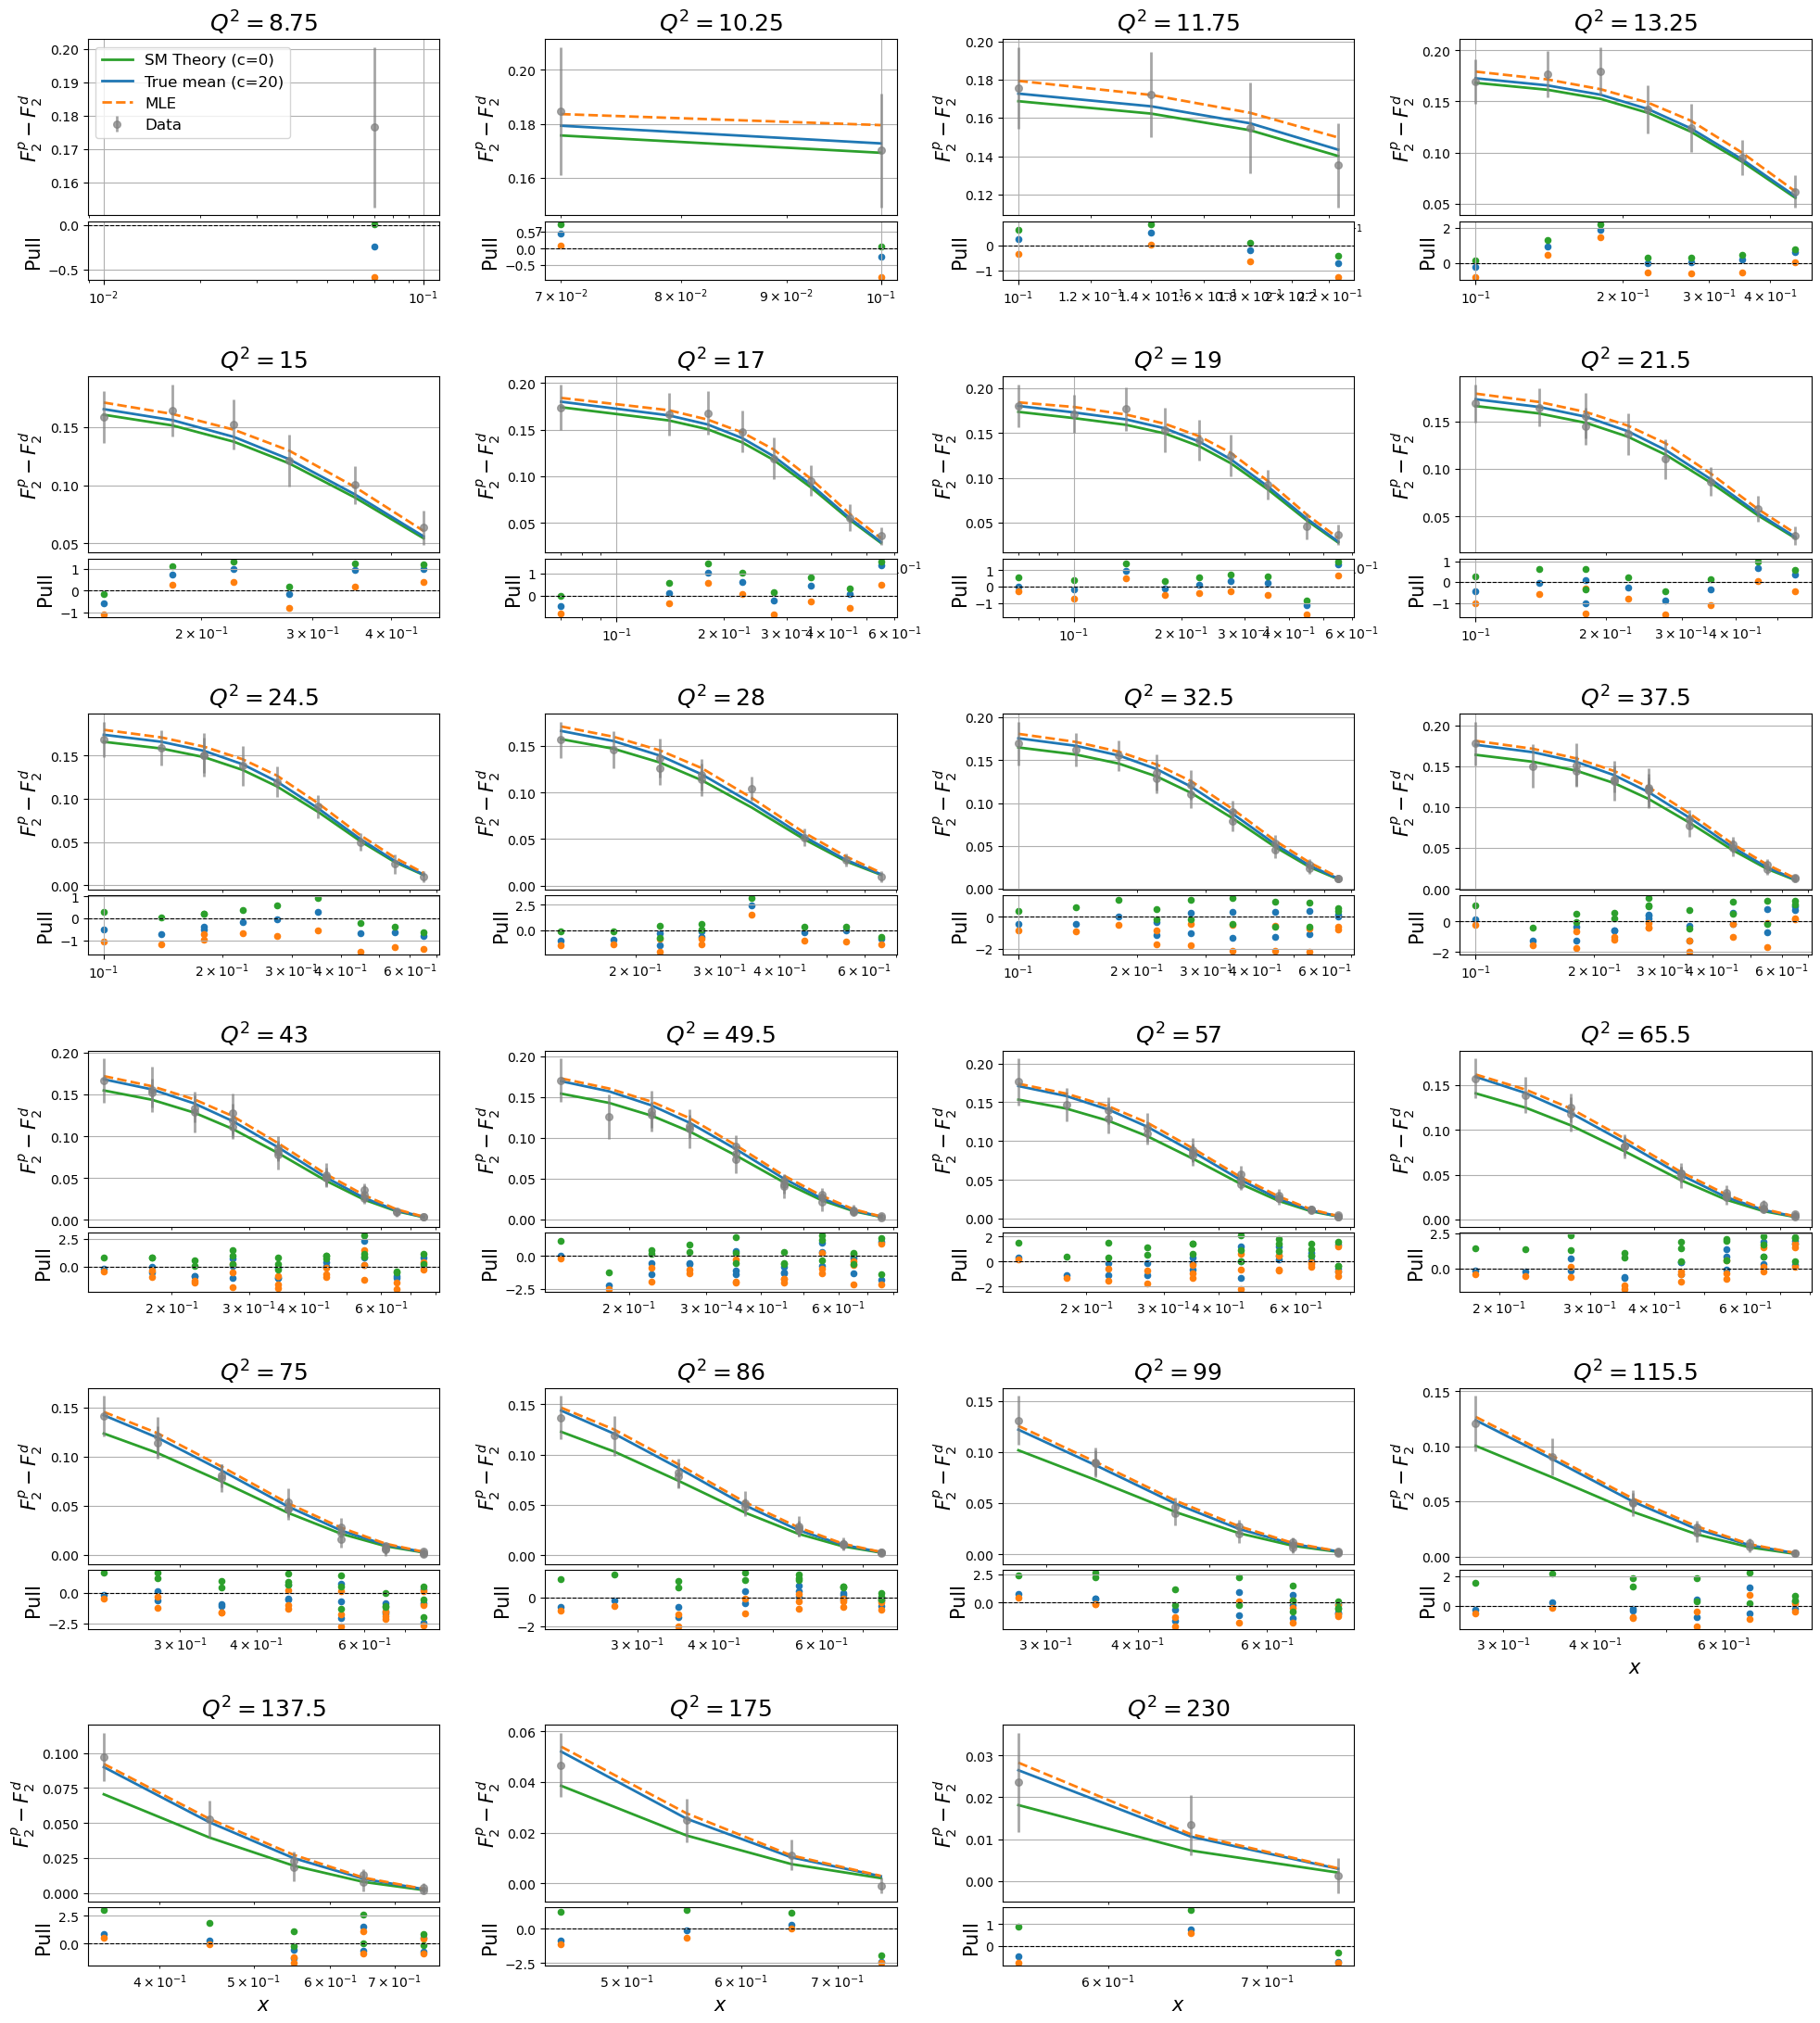

In [ ]:
# Mean prediction vs data
mu_hat      = true_mean_basis(c_hat,      beta_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
#mu_one_step = true_mean_basis(c_one_step, beta_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

fig = plot_by_Q2(
    {"SM Theory (c=0)": T, f"True mean (c={c_true})": mu, "MLE": mu_hat, "Data": D},#,"One-step": mu_one_step},
    xQ2=xQ2, ncols=4, x_log_scale=True, #q2_filter=lambda q2: (q2 > 75),
    series_styles={
        "SM Theory (c=0)": dict(linestyle="-",  linewidth=2, color="C2"),
        f"True mean (c={c_true})": dict(linestyle="-", linewidth=2, color="C0"),
        "MLE":       dict(linestyle="--",  linewidth=2, color="C1"),
        #"One-step":  dict(linestyle="-.", linewidth=2, color="C3"),
        "Data":      dict(kind="scatter", cov=Sigma, color="gray", s=30, alpha=0.7),
    },
    pull=[
        {"data": "Data", "ref": f"True mean (c={c_true})",  "color": "C0"},
        {"data": "Data", "ref": "MLE",               "color": "C1"},
        {"data": "Data", "ref": "SM Theory (c=0)",   "color": "C2"},
    ],
    pull_legend=False,
    legend_fontsize=12,
    label_fontsize=15,
    title_fontsize=18,
    y_label=r"$F_2^p-F_2^d$",
)
#fig.savefig("../results/F2p-F2d/kquad=0/data_fit_c=20_mle_one_step_unconstrained.pdf", bbox_inches="tight")

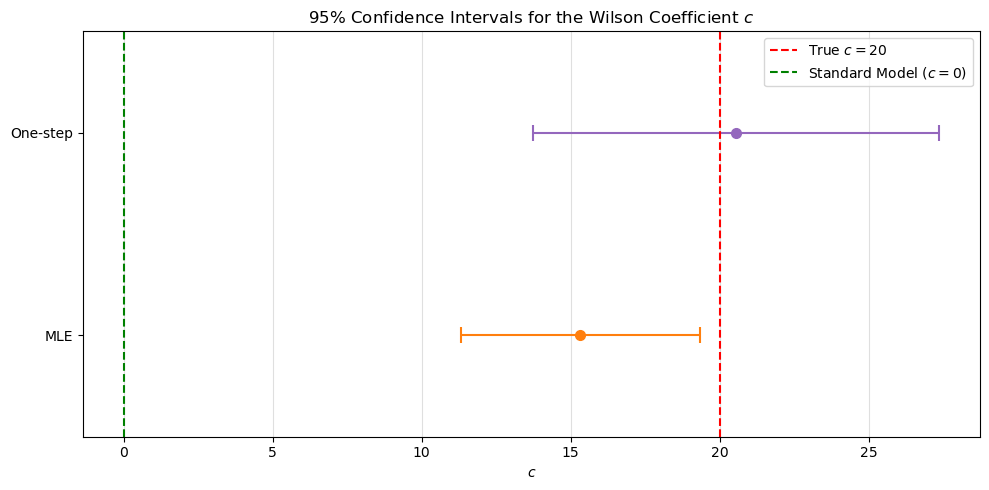

In [ ]:
# Compare confidence intervals between the original MLE-based bootstrap and the one-step analytical CI

labels    = ["MLE", "One-step"]#"Joint MLE\n(bootstrap)",
estimates = [c_hat_sep, c_one_step] #c_hat_joint, 
lowers    = [ci_sep_lower, ci_os_lower] #ci_joint_lower,
uppers    = [ci_sep_upper, ci_os_upper] #ci_joint_upper,
colors    = ["C1", "C4"]

y = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(10, 5))

for i, (est, lo, hi, color, label) in enumerate(zip(estimates, lowers, uppers, colors, labels)):
    ax.errorbar(est, y[i], xerr=[[est - lo], [hi - est]],
                fmt="o", capsize=6, capthick=1.5, linewidth=1.5,
                color=color, markersize=7)#, label=label)

ax.axvline(c_true, color="red", linestyle="--", linewidth=1.5, label=f"True $c = {c_true}$")
ax.axvline(0, color="green", linestyle="--", linewidth=1.5, label=f"Standard Model ($c = 0$)")

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_ylim(-0.5, len(labels) - 0.5)
ax.set_xlabel("$c$")
ax.set_title("95% Confidence Intervals for the Wilson Coefficient $c$")
ax.legend()
ax.grid(True, axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

#fig.savefig(f"../results/F2p-F2d/kquad=0/CI_95_c={c_true}_mle_one_step_unconstrained.pdf", bbox_inches="tight")

---
## 7. Simulation Study

We repeat the experiment $N_{\rm sim}$ times (each with a fresh draw of $\mathbf{D}$) to assess the
sampling distribution of the plug-in MLE and the one-step estimator.

`setup_experiment` pre-computes the basis and design matrix once; `run_single_experiment`
only generates new data and re-runs the optimization.

In [60]:
c_true = 20

zero_coeff = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))

setup_dict = setup_experiment(
    pdf=pdfset, c=c_true, f=f,
    xQ2=xQ2, grid=grid, W=W,
    degree=3, M=10,
    data_Sigma=Sigma,
    opt="separate",            # uses the "separate" or "joint" choice from Section 5
    parametrize=parametrize,
    c_opt="Nelder-Mead", beta_opt="SLSQP",
    c0=0, Lambda=Lambda,
    x_min=x_min, x_max=x_max,
    Q2_min=Q2_min, Q2_max=Q2_max,
    klin_fn=_klin, kquad_fn=zero_coeff,
    nonneg_beta=True, pin_endpoints=True,
    ncol_plots=2, x_log_scale=True,
    return_history=False, loss_scale=1e2,
    mle_constrained=False, one_step_constrained=False
)

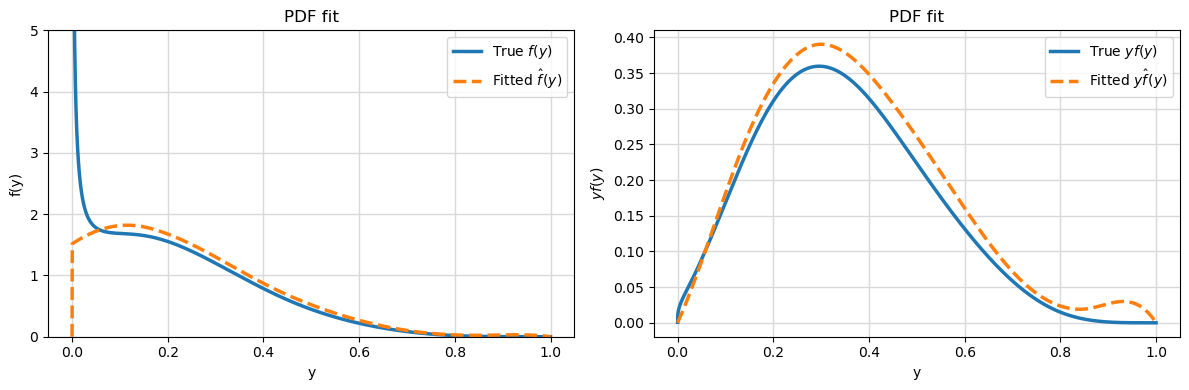

     Parameter      Value
0        c_hat  13.563272
1   c_one_step  20.562878
2       True c  20.000000
3       beta_0   0.000000
4       beta_1   0.072073
5       beta_2   0.288259
6       beta_3   0.428330
7       beta_4   0.334078
8       beta_5   0.189040
9       beta_6   0.045464
10      beta_7   0.000000
11      beta_8   0.048667
12      beta_9   0.000000
Normalization constraint (w^T beta_hat): 0.7421778164991576
Fitted pdf integrates to (xf parametrize): 0.7421778252444577


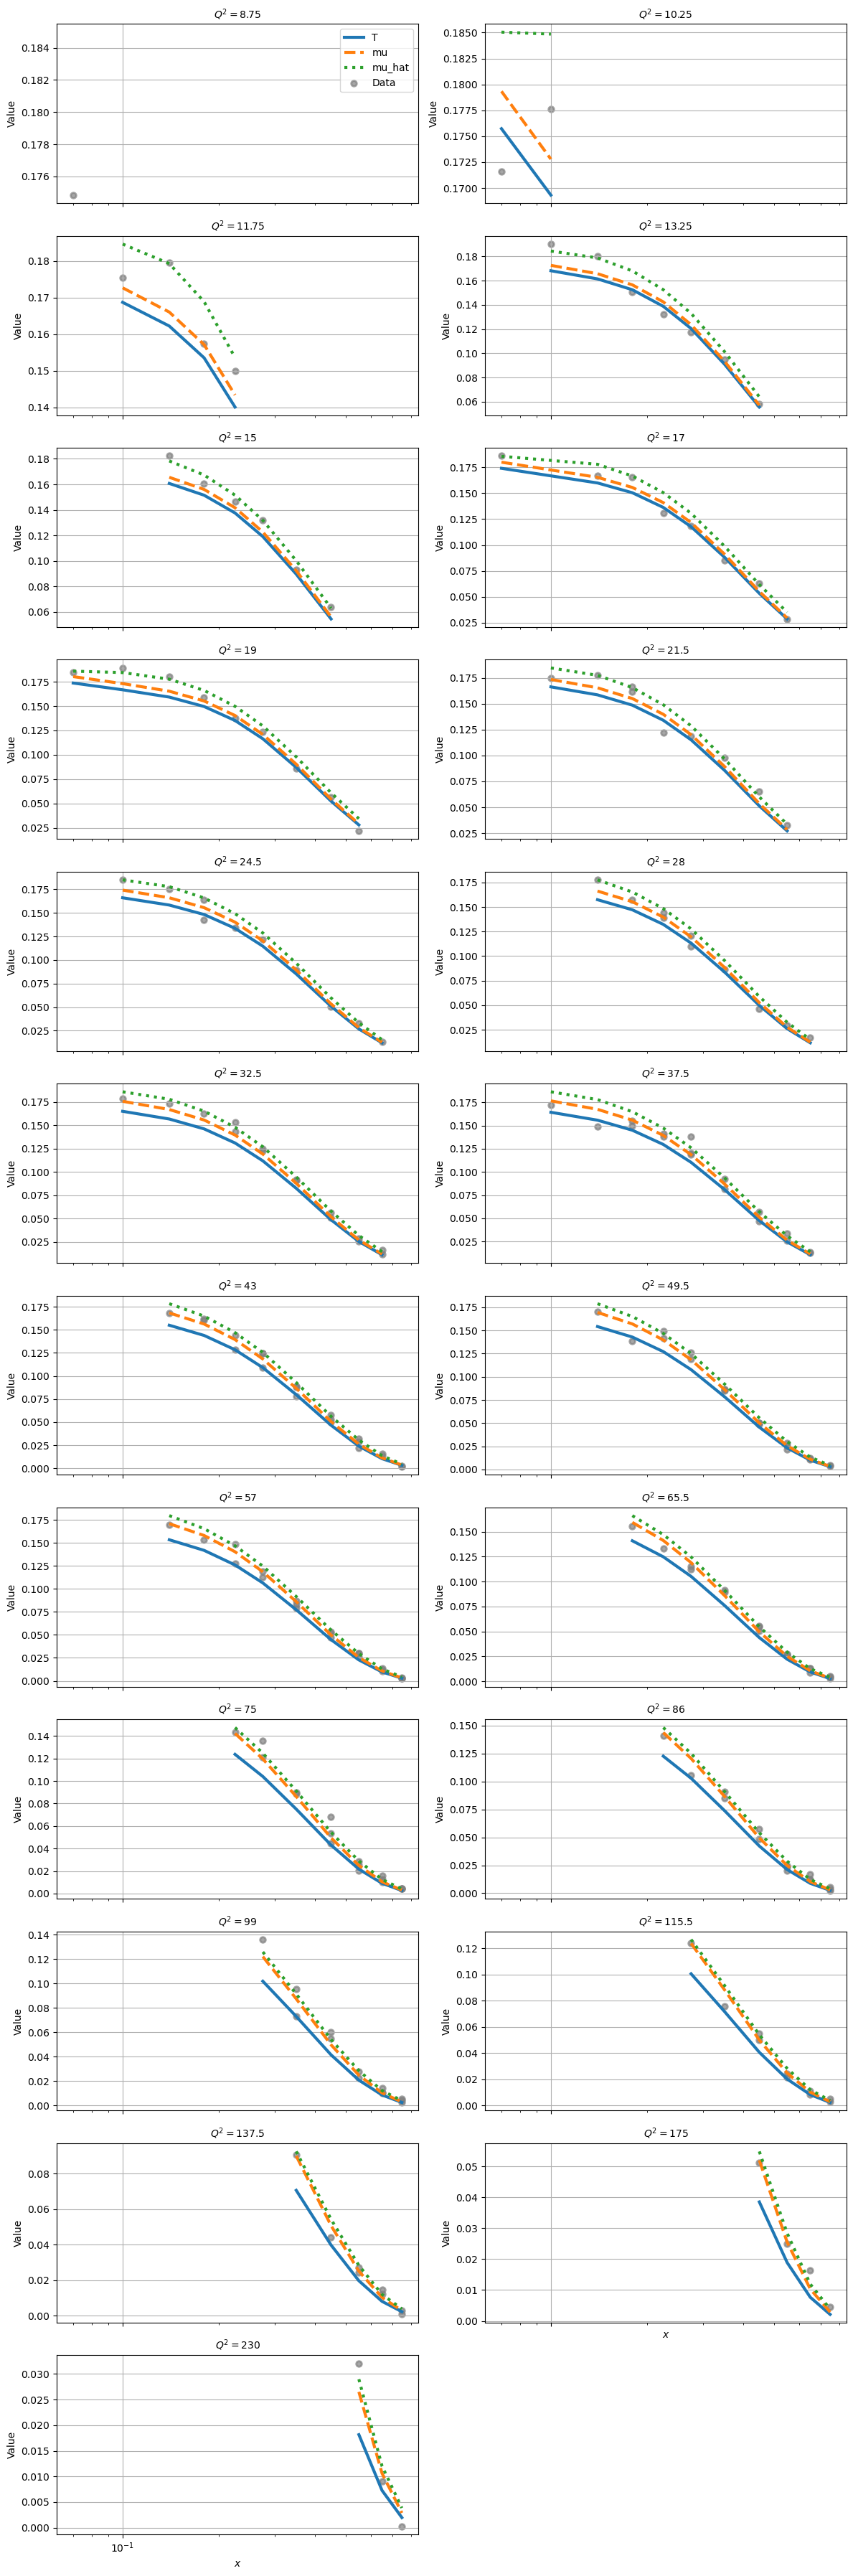

In [55]:
# Quick diagnostic on one draw before the full simulation
c_hat_diag, c_one_step_diag, info_diag = run_single_experiment(setup_dict, diagnostics=True)

In [61]:
N_sim = 1000
plug_in_estimates  = np.zeros(N_sim)
one_step_estimates = np.zeros(N_sim)
n_boot = 500
all_boot_samples = np.zeros((N_sim, n_boot))
CIs_mle      = np.zeros((N_sim, 2))
CIs_one_step = np.zeros((N_sim, 2))
one_step_SEs = np.zeros(N_sim)

A      = setup_dict['A']
w_norm = setup_dict['w_norm']
xQ2    = setup_dict['xQ2']
Sigma  = setup_dict['data_Sigma']

# Bootstrap must refit under the same constraint as the original MLE fit
# (see run_single_experiment: fit_w_norm = w_norm if mle_constrained else None)
boot_w_norm = w_norm if setup_dict['mle_constrained'] else None

print("MLE constrained:", setup_dict['mle_constrained'])
print("One-step constrained:", setup_dict['one_step_constrained'])
print("Bootstrap constrained:", boot_w_norm is not None)

for sim in range(N_sim):
    c_hat_i, c_one_step_i, info_i = run_single_experiment(setup_dict, diagnostics=True, show_plots=False)
    plug_in_estimates[sim]  = c_hat_i
    one_step_estimates[sim] = c_one_step_i

    ci_lower, ci_upper, se = one_step_confidence_interval(info_i['one_step'])
    CIs_one_step[sim] = (ci_lower, ci_upper)
    one_step_SEs[sim] = se

    ci_lower_b, ci_upper_b, boot_samples_i = bootstrap_confidence_interval(
        A=A, w_norm=boot_w_norm, xQ2=xQ2, Sigma=Sigma, c0=0.0,
        c_hat=c_hat_i, beta_hat=info_i['beta_hat'],
        n_boot=n_boot, alpha=0.05, estimator="mle",
        opt=setup_dict['opt'], c_opt=setup_dict['c_opt'],
        c_range=setup_dict['c_range'],
        klin=setup_dict['klin'], kquad=setup_dict['kquad'],
        verbose=False,
    )
    all_boot_samples[sim] = boot_samples_i
    CIs_mle[sim] = (ci_lower_b, ci_upper_b)

    if (sim + 1) % 10 == 0:
        print(f"  {sim+1}/{N_sim} done")

covered_one_step = (CIs_one_step[:, 0] <= c_true) & (CIs_one_step[:, 1] >= c_true)
covered_mle      = (CIs_mle[:, 0] <= c_true) & (CIs_mle[:, 1] >= c_true)

print("\n--- Results ---")
for label, est in [("Plug-in", plug_in_estimates), ("One-step", one_step_estimates)]:
    print(f"{label:10s}  mean={est.mean():.4f} median={np.median(est):.4f} bias={est.mean()-c_true:.4f} std={est.std():.4f}")
print(f"True c = {c_true}")
print(f"95% CI coverage (plug-in,  bootstrap):  {covered_mle.mean():.3f}")
print(f"95% CI coverage (one-step, analytical): {covered_one_step.mean():.3f}")

MLE constrained: False
One-step constrained: False
Bootstrap constrained: False
  10/1000 done
  20/1000 done
  30/1000 done
  40/1000 done
  50/1000 done
  60/1000 done
  70/1000 done
  80/1000 done
  90/1000 done
  100/1000 done
  110/1000 done
  120/1000 done
  130/1000 done
  140/1000 done
  150/1000 done
  160/1000 done
  170/1000 done
  180/1000 done
  190/1000 done
  200/1000 done
  210/1000 done
  220/1000 done
  230/1000 done
  240/1000 done
  250/1000 done
  260/1000 done
  270/1000 done
  280/1000 done
  290/1000 done
  300/1000 done
  310/1000 done
  320/1000 done
  330/1000 done
  340/1000 done
  350/1000 done
  360/1000 done
  370/1000 done
  380/1000 done
  390/1000 done
  400/1000 done
  410/1000 done
  420/1000 done
  430/1000 done
  440/1000 done
  450/1000 done
  460/1000 done
  470/1000 done
  480/1000 done
  490/1000 done
  500/1000 done
  510/1000 done
  520/1000 done
  530/1000 done
  540/1000 done
  550/1000 done
  560/1000 done
  570/1000 done
  580/1000 done
 

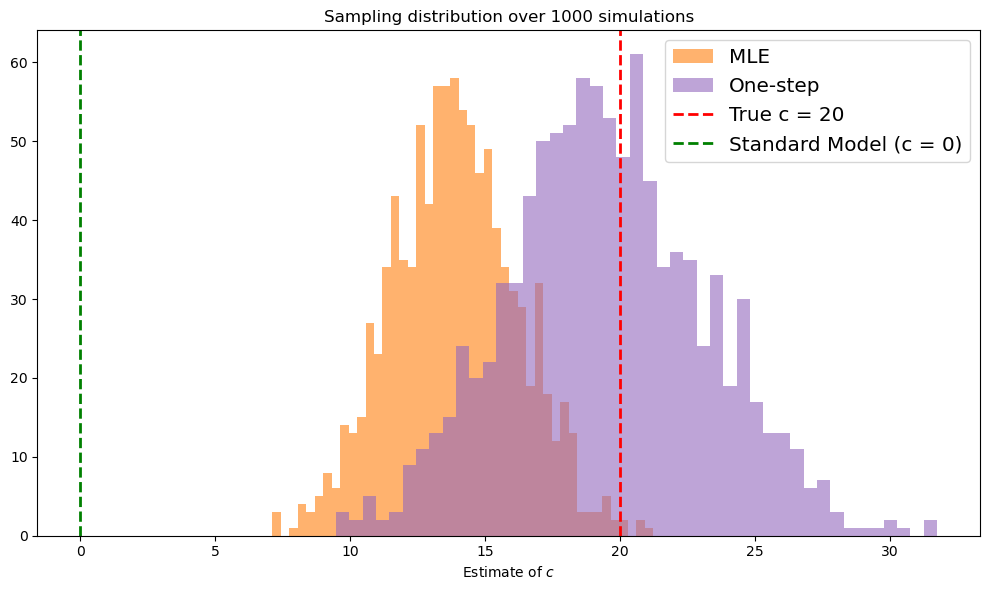

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(plug_in_estimates,  bins=45, alpha=0.6, color="C1", label="MLE")
ax.hist(one_step_estimates, bins=45, alpha=0.6, color="C4", label="One-step")
ax.axvline(c_true, color="red", linestyle="--", linewidth=2, label=f"True c = {c_true}")
ax.axvline(0, color="green", linestyle="--", linewidth=2, label=f"Standard Model (c = 0)")
ax.set_xlabel("Estimate of $c$")
ax.set_title(f"Sampling distribution over {N_sim} simulations")
ax.legend(fontsize='x-large')
plt.tight_layout(); plt.show()
#fig.savefig(f"../results/F2p-F2d/kquad=0/sampling_dist_c={c_true}_mle_one_step_unconstrained.pdf", bbox_inches="tight")

---
## 8. Uncertainty Quantification

Three diagnostics to check that the one-step confidence interval is working correctly:

1. **CI strip plot** — each of the $N_{\rm sim}$ CIs drawn as a bar; blue = covers $c_{\rm true}$, red = misses.
2. **Coverage comparison** — bar chart of empirical coverage rates for the MLE bootstrap CI and the one-step analytical CI, both at the nominal level.
3. **CI width distribution** — boxplot of CI widths across replicates for each method.
4. **Coverage curve** — empirical coverage at each nominal level.


In [ ]:
# ── CI strip plot ────────────────────────────────────────────────────
covered = covered_one_step
colors = ['C0' if cov else 'C3' for cov in covered]

fig, ax = plt.subplots(figsize=(8, max(5, N_sim // 8)))
for i in range(N_sim):
    ax.plot([CIs_one_step[i, 0], CIs_one_step[i, 1]], [i, i], color=colors[i], lw=1.0, alpha=0.8)
    ax.plot(one_step_estimates[i], i, 'o', color=colors[i], ms=2.5)

ax.axvline(c_true, color='black', lw=2, ls='--', zorder=5)
ax.legend(handles=[
    Line2D([0], [0], color='C0', lw=2, label=f'Covered ({covered.sum()}/{N_sim})'),
    Line2D([0], [0], color='C3', lw=2, label=f'Missed ({(~covered).sum()}/{N_sim})'),
    Line2D([0], [0], color='black', lw=2, ls='--', label=f'True $c = {c_true}$'),
], fontsize=12)
ax.set_xlabel('$c$', fontsize=13)
ax.set_ylabel('Simulation index')
ax.set_title(f'95% CIs (one-step) — empirical coverage {covered.mean()*100:.1f}%', fontsize=13)
plt.tight_layout(); plt.show()


/var/folders/qm/350m2x392jj9m78jcv5zmhx80000gn/T/ipykernel_18204/3479101283.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(widths, labels=labels, patch_artist=True,


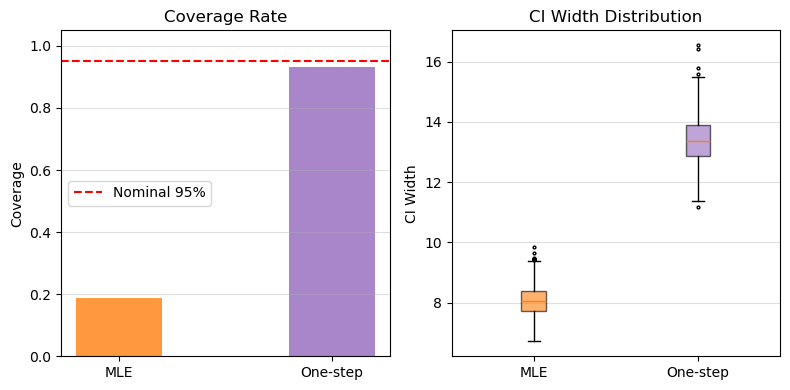

In [ ]:
labels    = ["MLE", "One-step"]
CI_arrays = [CIs_mle, CIs_one_step]
colors    = ["C1", "C4"]

alpha     = 0.05
coverages = [((CI[:, 0] <= c_true) & (CI[:, 1] >= c_true)).mean() for CI in CI_arrays]
widths    = [CI[:, 1] - CI[:, 0] for CI in CI_arrays]
se_cov    = [np.sqrt(cov * (1 - cov) / N_sim) for cov in coverages]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

ax = axes[0]
x = np.arange(len(labels))
for i, (cov, se, color) in enumerate(zip(coverages, se_cov, colors)):
    ax.bar(x[i], cov, capsize=5, color=color, alpha=0.8, width=0.4)#, yerr=se)
ax.axhline(1 - alpha, color="red", linestyle="--", linewidth=1.5,
           label=f"Nominal {int((1-alpha)*100)}%")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Coverage")
ax.set_title("Coverage Rate")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, axis="y", alpha=0.4)

ax = axes[1]
bp = ax.boxplot(widths, labels=labels, patch_artist=True,
                flierprops=dict(marker='.', markersize=4))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_ylabel("CI Width")
ax.set_title("CI Width Distribution")
ax.grid(True, axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

#fig.savefig(f"../results/F2p-F2d/kquad=0/coverage_width_c={c_true}_mle_one_step_unconstrained.pdf", bbox_inches="tight")


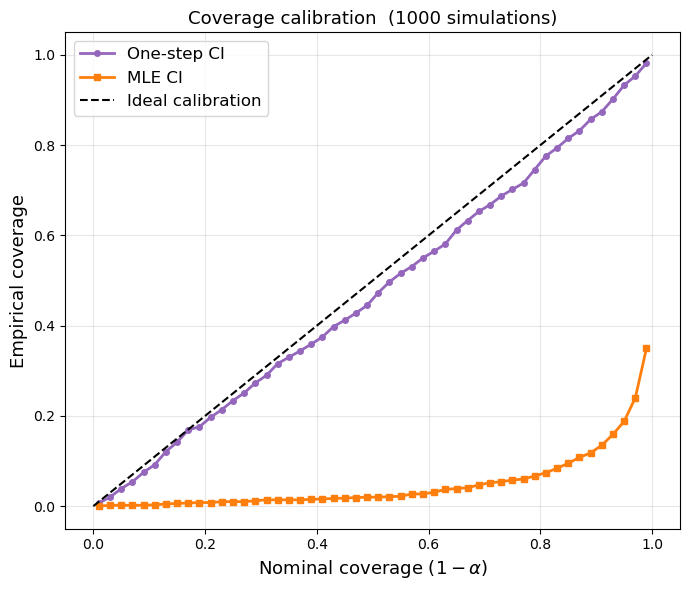

In [ ]:
se_boot = np.nanstd(all_boot_samples, axis=1, ddof=1)  # (N_sim,)

alphas     = np.linspace(0.01, 0.99, 50)
nom_levels = 1 - alphas
emp_cov_one_step = []
emp_cov_mle_boot = []

for a in alphas:
    z = norm.ppf(1 - a / 2)

    lo = one_step_estimates - z * one_step_SEs
    hi = one_step_estimates + z * one_step_SEs
    emp_cov_one_step.append(np.mean((lo <= c_true) & (hi >= c_true)))

    lo = plug_in_estimates - z * se_boot
    hi = plug_in_estimates + z * se_boot
    emp_cov_mle_boot.append(np.mean((lo <= c_true) & (hi >= c_true)))

emp_cov_one_step = np.array(emp_cov_one_step)
emp_cov_mle_boot = np.array(emp_cov_mle_boot)


fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(nom_levels, emp_cov_one_step, 'o-', color='C4', lw=2, ms=4, label='One-step CI')
ax.plot(nom_levels, emp_cov_mle_boot, 's-', color='C1', lw=2, ms=4, label='MLE CI')
ax.plot([0.0, 1], [0.0, 1], 'k--', lw=1.5, label='Ideal calibration')
ax.set_xlabel('Nominal coverage $(1 - \\alpha)$', fontsize=13)
ax.set_ylabel('Empirical coverage', fontsize=13)
ax.set_title(f'Coverage calibration  ({N_sim} simulations)', fontsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#fig.savefig(f"../results/F2p-F2d/kquad=0/coverage_calibration_c={c_true}_mle_one_step_unconstrained.pdf", bbox_inches="tight")


In [66]:
# save simulation results for later analysis
np.savez(f"simulation_results/kquad=0/c={c_true}_mle_one_step_unconstrained_Nelder-Mead.npz",
          all_boot_samples=all_boot_samples, one_step_estimates=one_step_estimates,
          plug_in_estimates=plug_in_estimates, CIs_one_step=CIs_one_step, CIs_mle=CIs_mle,
          one_step_SEs=one_step_SEs, c_true=c_true, N_sim=N_sim)

In [22]:
# read back the saved results
results = np.load("simulation_results/kquad=0/c=20_mle_one_step_unconstrained_Nelder-Mead.npz")
all_boot_samples = results["all_boot_samples"]
one_step_estimates = results["one_step_estimates"]
plug_in_estimates = results["plug_in_estimates"]
CIs_one_step = results["CIs_one_step"]
CIs_mle = results["CIs_mle"]
one_step_SEs = results["one_step_SEs"]
c_true = results["c_true"].item()
N_sim = results["N_sim"].item()